In [58]:
import pandas as pd
df=pd.read_csv('/content/Wholesale customers data.csv')
df

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [59]:
print(df.columns)

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')


In [60]:
#customer segmentation based on these features('Fresh', 'Milk', 'Grocery', 'Frozen','Detergents_Paper', 'Delicassen')
#channel and region doesnt depend on product spending so we are not using them

In [61]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [62]:
print(df.tail())

     Channel  Region  Fresh   Milk  Grocery  Frozen  Detergents_Paper  \
435        1       3  29703  12051    16027   13135               182   
436        1       3  39228   1431      764    4510                93   
437        2       3  14531  15488    30243     437             14841   
438        1       3  10290   1981     2232    1038               168   
439        1       3   2787   1698     2510      65               477   

     Delicassen  
435        2204  
436        2346  
437        1867  
438        2125  
439          52  


In [63]:
#shape
print(df.shape)
print(df.info())

(440, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB
None


In [64]:
#duplicates
print(df.duplicated().sum())

0


In [65]:
print(df['Channel'].value_counts())
df['Region'].value_counts()

Channel
1    298
2    142
Name: count, dtype: int64


,count
Region,
3,316
1,77
2,47


In [66]:
print(df.isnull().sum())

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [67]:
x=df[['Fresh', 'Milk', 'Grocery', 'Frozen','Detergents_Paper', 'Delicassen']]
#we are not considering channel and region as we are checking spending patterns
x

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...
435,29703,12051,16027,13135,182,2204
436,39228,1431,764,4510,93,2346
437,14531,15488,30243,437,14841,1867
438,10290,1981,2232,1038,168,2125


In [68]:
#feature scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled

array([[ 0.05293319,  0.52356777, -0.04111489, -0.58936716, -0.04356873,
        -0.06633906],
       [-0.39130197,  0.54445767,  0.17031835, -0.27013618,  0.08640684,
         0.08915105],
       [-0.44702926,  0.40853771, -0.0281571 , -0.13753572,  0.13323164,
         2.24329255],
       ...,
       [ 0.20032554,  1.31467078,  2.34838631, -0.54337975,  2.51121768,
         0.12145607],
       [-0.13538389, -0.51753572, -0.60251388, -0.41944059, -0.56977032,
         0.21304614],
       [-0.72930698, -0.5559243 , -0.57322717, -0.62009417, -0.50488752,
        -0.52286938]])

In [69]:
#model building
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,11):
  kmeans=KMeans(n_clusters=i,init='k-means++',random_state=41)
  #training
  kmeans.fit(x_scaled)
  #inertia
  wcss.append(kmeans.inertia_)
wcss

[2639.9999999999977,
 1956.1242775222677,
 1619.952782172456,
 1315.9419330772062,
 1210.7644706676429,
 978.2215984538889,
 822.7702050192365,
 784.4056841841456,
 701.0232208676563,
 657.6459635205324]

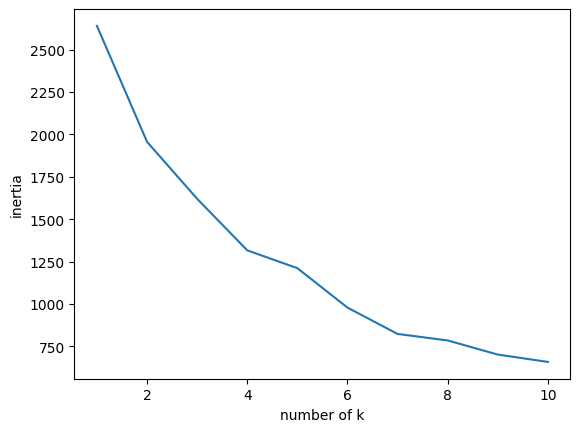

In [70]:
#elbow method
import matplotlib.pyplot as plt
plt.plot(range(1,11),wcss)
plt.xlabel('number of k')
plt.ylabel('inertia')
plt.show()

In [71]:
#model building using k=7
kmeans=KMeans(n_clusters=7,init='k-means++',random_state=41)
#training
clust_mod=kmeans.fit(x_scaled)
labels=clust_mod.labels_
labels

array([2, 2, 2, 0, 3, 0, 0, 2, 0, 2, 2, 0, 3, 2, 2, 0, 2, 0, 2, 0, 0, 0,
       3, 1, 2, 0, 0, 0, 1, 3, 0, 0, 0, 3, 0, 2, 3, 2, 2, 3, 3, 0, 2, 1,
       2, 1, 2, 4, 2, 1, 0, 0, 3, 2, 3, 0, 1, 2, 0, 2, 0, 4, 2, 2, 0, 1,
       0, 2, 0, 0, 0, 2, 0, 0, 2, 0, 0, 1, 0, 0, 0, 2, 2, 0, 0, 4, 4, 3,
       0, 3, 0, 0, 1, 6, 2, 0, 2, 0, 0, 0, 2, 2, 2, 3, 0, 0, 2, 2, 2, 2,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 3, 3, 0, 2, 0, 3, 0, 0,
       0, 0, 0, 0, 2, 2, 0, 0, 0, 3, 3, 0, 0, 1, 0, 0, 0, 3, 0, 0, 0, 0,
       0, 1, 2, 0, 2, 2, 2, 0, 0, 1, 2, 2, 2, 0, 0, 0, 2, 1, 2, 2, 0, 2,
       3, 0, 0, 0, 2, 3, 2, 5, 0, 0, 0, 2, 2, 2, 0, 0, 0, 2, 0, 0, 3, 2,
       0, 0, 1, 1, 3, 0, 0, 1, 0, 2, 0, 1, 0, 1, 0, 2, 2, 2, 1, 0, 2, 0,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0,
       0, 0, 2, 2, 0, 0, 0, 0, 0, 1, 0, 3, 2, 3, 0, 0, 3, 3, 0, 0, 0, 0,
       2, 2, 2, 0, 2, 0, 0, 0, 0, 3, 0, 0, 3, 0, 0, 2, 0, 0, 3, 3, 3, 3,
       0, 0, 0, 3, 0, 0, 0, 2, 0, 0, 0, 0, 2, 0, 0,

In [72]:
df['cluster']=kmeans.labels_
df

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,0
4,2,3,22615,5410,7198,3915,1777,5185,3
...,...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204,3
436,1,3,39228,1431,764,4510,93,2346,3
437,2,3,14531,15488,30243,437,14841,1867,1
438,1,3,10290,1981,2232,1038,168,2125,0


In [ ]:
print(df['cluster'].value_counts())

In [77]:
#new prediction
new_customer=pd.DataFrame({'Fresh':[12000],'Milk':[5000],'Grocery':[8000],'Frozen':[1500],
                           'Detergents_Paper':[2000],'Delicassen':[1000]})
new_customer_scaled=scaler.transform(new_customer)
cluster=kmeans.predict(new_customer_scaled)
print("prediction:",cluster[0])

prediction: 0


In [78]:
#PERFORMANCE EVALUATION
from sklearn.metrics import silhouette_samples
print(silhouette_samples(x_scaled,labels))

[ 0.08523275  0.27125566  0.10096675  0.44141712 -0.09100132  0.12779798
  0.23097805  0.08405624  0.31241359  0.36973816  0.29999129  0.51778521
 -0.02286512  0.20565562  0.17552895  0.49860413  0.39468763  0.18076021
  0.0017044   0.16823755  0.29076542  0.54777013  0.18068125  0.0534236
  0.15964145  0.11233794  0.56754655  0.5161143   0.17626927  0.26914965
  0.07878518  0.41960764  0.41620571  0.08737914  0.45206565  0.2497414
  0.0608938   0.34395204  0.31855835  0.35785989  0.04683144  0.2525026
  0.37702271 -0.06993573  0.23291029  0.06196116  0.22142883  0.25788886
  0.26843227  0.39140231  0.48683175  0.2388476   0.24379036  0.39990486
 -0.18491264  0.33660559  0.36699707  0.42535392  0.52634607  0.03430747
  0.07617937  0.19955211 -0.04552878  0.42122774  0.4889064   0.35018957
  0.1196079   0.19430211  0.19075627  0.52027228  0.25398151  0.03306363
  0.29791497  0.21597659  0.01624247  0.41825826  0.28021566  0.25331108
  0.56685317  0.36112929  0.51553324  0.4333845   0.29